# Step 8, checked more strictly (added after looking)

These checks were **not** in the holdout plan. They were added after the results were seen, so read them as a stricter second look, not as new tests.
No model is run again: everything here reuses the predictions saved by `holdout.ipynb`.

1. **Many tests.** The holdout has 123 significance tests. With that many, some look significant by luck alone.
   Holm's method corrects for that: within each planned comparison, the smallest p-value is multiplied by the number of tests, the next by one fewer, and so on.
2. **Ranges.** How far each key number could move by chance. Resample whole weeks 2,000 times and take the middle 95%.
   Whole weeks stay together because nearby days are related.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

from charts import AXIS, INK_SOFT, LIGHT_BLUE, dots, new_chart, reference_line, save
from data import MARKETS, load_market
from evaluation import bootstrap_range, holm, mcnemar, paired_loss_test
from models import pooled
from volatility import qlike

RESULTS = Path("results")
PAPER_MODELS = ["LDA", "Logistic regression", "KNN", "SVM", "Random forest", "AdaBoost", "Neural network"]
SEEDS = [0, 1, 2]

def load(name):
    """One saved holdout run per market."""
    return {market: pd.read_pickle(RESULTS / f"holdout_{name}_{market}.pkl") for market in MARKETS}

paper = {model: load(f"paper_{model}") for model in PAPER_MODELS}
us_close = load("us_close")
open_to_close = {"Philippines": pd.read_pickle(RESULTS / "holdout_open_lr_Philippines.pkl"),
                 "Malaysia": pd.read_pickle(RESULTS / "holdout_open_forest_Malaysia.pkl")}
har, har_us, garch = load("har"), load("har_us"), load("garch")
gru = {seed: load(f"gru_seed{seed}") for seed in SEEDS}
same = {market: p.assign(predicted=p["same_as_yesterday"]) for market, p in har.items()}
india = us_close["India"]

## 1. Many tests

Each row is one planned comparison. **Before** counts the tests with p < 0.05 as first reported; **after** counts them once adjusted.

In [2]:
def squared_error(p):
    return (p["predicted"] - p["actual"]) ** 2

def against_fair_bar(runs):
    return pd.Series({market: pooled(p)["p vs fair"] for market, p in runs.items()})

def against_har(rival, loss):
    return pd.Series({market: paired_loss_test(loss(rival[market]), loss(har[market])) for market in MARKETS})

p_values = {
    "1. Paper's models vs fair bar": pd.concat({model: against_fair_bar(runs) for model, runs in paper.items()}),
    "2. US move, close-to-close vs fair bar": against_fair_bar(us_close),
    "3. US move, open-to-close vs fair bar": against_fair_bar(open_to_close),
    "4. India, same as yesterday vs fair bar": pd.Series({"India": mcnemar(india["up"], india["same_as_yesterday"], india["fair_call"])[2]}),
}
for score, loss in {"squared errors": squared_error, "QLIKE": qlike}.items():
    p_values[f"5. HAR vs same as yesterday, {score}"] = against_har(same, loss)
    p_values[f"5. HAR vs GARCH, {score}"] = against_har(garch, loss)
    p_values[f"5. HAR vs GRU (3 seeds), {score}"] = pd.concat({seed: against_har(gru[seed], loss) for seed in SEEDS})
    p_values[f"5. HAR + US vs HAR, {score}"] = against_har(har_us, loss)

adjusted = {name: holm(p) for name, p in p_values.items()}
counts = pd.DataFrame({
    "tests": {name: len(p) for name, p in p_values.items()},
    "p < 0.05 before": {name: (p < 0.05).sum() for name, p in p_values.items()},
    "p < 0.05 after": {name: (p < 0.05).sum() for name, p in adjusted.items()},
})
display(counts)
counts.sum().to_frame("all comparisons").T

,tests,p < 0.05 before,p < 0.05 after
1. Paper's models vs fair bar,42,2,0
"2. US move, close-to-close vs fair bar",6,4,2
"3. US move, open-to-close vs fair bar",2,1,0
"4. India, same as yesterday vs fair bar",1,0,0
"5. HAR vs same as yesterday, squared errors",6,6,6
"5. HAR vs GARCH, squared errors",6,5,1
"5. HAR vs GRU (3 seeds), squared errors",18,2,0
"5. HAR + US vs HAR, squared errors",6,1,0
"5. HAR vs same as yesterday, QLIKE",6,6,6
"5. HAR vs GARCH, QLIKE",6,4,3


,tests,p < 0.05 before,p < 0.05 after
all comparisons,123,36,20


The p-values behind the rows that changed, before and after:

In [3]:
for name in ["2. US move, close-to-close vs fair bar", "3. US move, open-to-close vs fair bar",
             "5. HAR vs GARCH, squared errors", "5. HAR vs GARCH, QLIKE", "5. HAR + US vs HAR, squared errors"]:
    print(name)
    display(pd.DataFrame({"before": p_values[name], "after": adjusted[name]}).T.round(3))

print("5. HAR vs GRU: the tests with p < 0.05 before adjusting")
for score in ["squared errors", "QLIKE"]:
    name = f"5. HAR vs GRU (3 seeds), {score}"
    table = pd.DataFrame({"before": p_values[name], "after": adjusted[name]})
    display(table[table["before"] < 0.05].round(3).rename_axis(["seed", score]))

2. US move, close-to-close vs fair bar


,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
before,0.008,0.001,0.021,0.138,0.130,0.049
after,0.039,0.006,0.082,0.259,0.259,0.147


3. US move, open-to-close vs fair bar


,Philippines,Malaysia
before,0.044,0.528
after,0.088,0.528


5. HAR vs GARCH, squared errors


,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
before,0.0,0.022,0.117,0.044,0.017,0.014
after,0.0,0.069,0.117,0.088,0.069,0.069


... (3 outputs left out)

,Indonesia,Malaysia,Philippines,Singapore,Thailand,India
before,0.029,0.747,0.598,0.522,0.995,0.64
after,0.171,1.000,1.000,1.000,1.000,1.00


5. HAR vs GRU: the tests with p < 0.05 before adjusting


,,before,after
seed,squared errors,,
0,Thailand,0.008,0.139
1,Thailand,0.016,0.272


before  after
seed QLIKE                  
0    Malaysia   0.034  0.481
     Thailand   0.001  0.011
1    Malaysia   0.015  0.229
     Thailand   0.000  0.006
2    Thailand   0.004  0.070

- **36 of the 123 tests had p < 0.05 as first reported. 20 remain after adjusting.**
- **What holds:** nothing in the paper's setup beats the fair bar (the 2 significant results were both *below* it, and neither survives). HAR beats "same as yesterday" in all six markets on both scores.
- **The US move, close-to-close:** significant in two markets (Malaysia, Indonesia) instead of four. The six markets together are still clearly above the bar: see the ranges below.
- **The Philippines' open-to-close edge is no longer significant:** p goes from 0.044 to 0.088.
- **HAR vs GARCH:** five significant markets become one on squared errors (four others sit at 0.07-0.09), and four become three on QLIKE.
- **HAR vs GRU:** none of the 18 runs is significant on squared errors. On QLIKE, two remain, both in Thailand.
- **HAR + US:** its one significant result (worse than HAR in Indonesia) goes too. The US move neither helps nor hurts.

## 2. Ranges

### Direction

Accuracy minus the fair bar, in points. The paper's models are scored on all six markets together.

In [4]:
def accuracy_gap(p):
    """Accuracy minus the fair bar, in points."""
    return 100 * (((p["p_up"] > 0.5) == p["up"]).mean() - (p["fair_call"] == p["up"]).mean())

def same_as_yesterday_gap(p):
    return 100 * ((p["same_as_yesterday"] == p["up"]).mean() - (p["fair_call"] == p["up"]).mean())

def with_range(daily, statistic):
    """The number itself and its 95% range."""
    low, high = bootstrap_range(daily, statistic)
    return {"value": statistic(daily), "low": low, "high": high}

direction = {}
for model, runs in paper.items():
    direction["1. own past prices", model] = with_range(pd.concat(runs.values()), accuracy_gap)
direction["2. US move, close-to-close", "all six markets"] = with_range(pd.concat(us_close.values()), accuracy_gap)
for market, p in us_close.items():
    direction["2. US move, close-to-close", market] = with_range(p, accuracy_gap)
for market, p in open_to_close.items():
    direction["3. US move, open-to-close", market] = with_range(p, accuracy_gap)
direction["4. same as yesterday", "India"] = with_range(india, same_as_yesterday_gap)
direction = pd.DataFrame(direction).T
direction.round(1)

value  low  high
1. own past prices         LDA                   -1.0 -2.6   0.7
                           Logistic regression   -0.3 -1.7   1.1
                           KNN                   -0.5 -2.4   1.3
                           SVM                   -0.5 -1.7   0.8
                           Random forest         -0.1 -1.9   1.7
                           AdaBoost              -1.0 -2.9   0.9
                           Neural network        -0.1 -2.1   1.8
2. US move, close-to-close all six markets        4.3  2.2   6.3
                           Indonesia              4.5  1.5   7.5
                           Malaysia               7.4  3.0  11.4
                           Philippines            4.7  0.8   8.5
                           Singapore              3.3 -1.2   8.0
                           Thailand               2.6 -0.6   5.9
                           India                  3.3  0.3   6.3
3. US move, open-to-close  Philippines            4.5  0.3   8.5
                           Malaysia               1.6 -3.2   6.1
4. same as yesterday       India                 -0.8 -5.7   4.1

### Money

The average open-to-close return on the days each model buys, in % and before costs.

In [5]:
rows = {}
for market, p in open_to_close.items():
    df = load_market(market, include_holdout=True).loc[p.index]
    bought = (df["Close"] / df["Open"] - 1)[p["p_up"] > 0.5].to_frame("day_return")
    rows[market] = with_range(bought, lambda days: 100 * days["day_return"].mean())
pd.DataFrame(rows).T.round(3)

,value,low,high
Philippines,-0.025,-0.097,0.047
Malaysia,0.030,-0.016,0.075


### Volatility

HAR's R2, and its lead over each rival (positive = HAR better; for HAR + US, positive = the US move helps).

In [6]:
def r2(p, column="predicted"):
    """R2 against the average so far."""
    error, error_of_average = p[column] - p["actual"], p["average_so_far"] - p["actual"]
    return 1 - (error ** 2).sum() / (error_of_average ** 2).sum()

COMPARISONS = {
    "HAR R2": r2,
    "HAR minus GARCH": lambda p: r2(p) - r2(p, "garch"),
    "HAR minus GRU (mean of 3 seeds)": lambda p: r2(p) - np.mean([r2(p, f"gru{seed}") for seed in SEEDS]),
    "HAR + US minus HAR": lambda p: r2(p, "har_us") - r2(p),
}

volatility = {}
for market in MARKETS:
    everyone = har[market].assign(garch=garch[market]["predicted"], har_us=har_us[market]["predicted"],
                                  **{f"gru{seed}": gru[seed][market]["predicted"] for seed in SEEDS})
    for name, statistic in COMPARISONS.items():
        volatility[name, market] = with_range(everyone, statistic)
volatility = pd.DataFrame(volatility).T
volatility.round(3)

,,value,low,high
HAR R2,Indonesia,0.471,0.386,0.538
HAR minus GARCH,Indonesia,0.103,0.064,0.147
HAR minus GRU (mean of 3 seeds),Indonesia,0.003,-0.008,0.014
HAR + US minus HAR,Indonesia,-0.008,-0.015,-0.001
HAR R2,Malaysia,0.115,0.044,0.179
HAR minus GARCH,Malaysia,0.075,0.013,0.155
HAR minus GRU (mean of 3 seeds),Malaysia,0.011,-0.005,0.026
HAR + US minus HAR,Malaysia,-0.001,-0.011,0.007
HAR R2,Philippines,0.058,0.006,0.108
HAR minus GARCH,Philippines,0.030,-0.007,0.064


- **The paper's models:** every range includes zero, and none reaches +2 points. So an edge larger than about 2 points is ruled out, not just "not found".
- **The US move, close-to-close:** +4.3 points for the six markets together (2.2 to 6.3). The range is above zero in four single markets: Indonesia, Malaysia, the Philippines and India.
- **The Philippines, open-to-close:** accuracy is 4.5 points above the bar (0.3 to 8.5), but the average day it buys earns -0.03% (-0.10% to 0.05%). Even the top of that range is below a 0.1% trading cost. Malaysia's is 0.030% (-0.016% to 0.075%).
- **India, same as yesterday:** -0.8 points (-5.7 to 4.1). One market and 886 days can't say much either way.
- **HAR's R2 is above zero in all six markets,** though only just in the Philippines (0.006 to 0.108).
- **HAR's lead over GARCH** is above zero in four of six markets. **Its lead over the GRU** is above zero only in Thailand.
- **Adding the US move to HAR** changes R2 by less than 0.01 everywhere.

## Charts for the README

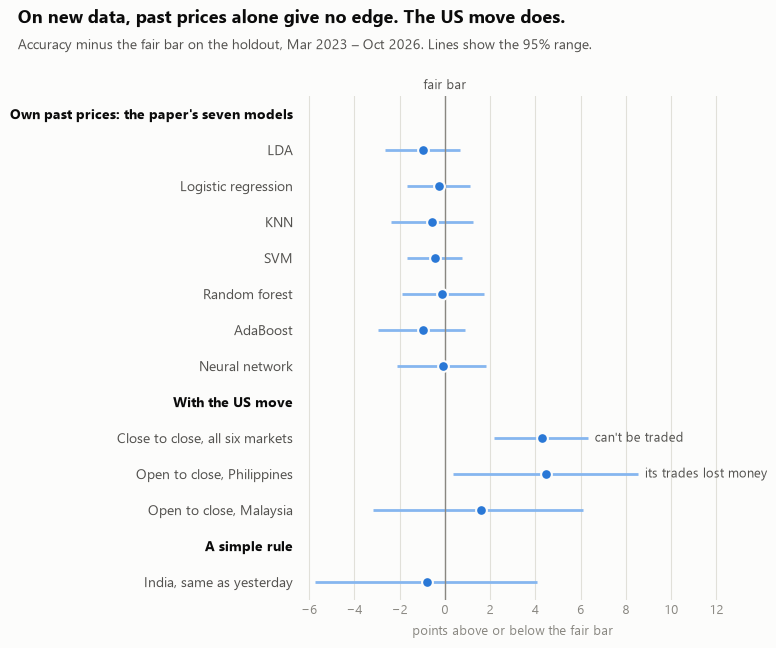

In [7]:
groups = {
    "Own past prices: the paper's seven models": direction.loc["1. own past prices"],
    "With the US move": pd.concat([
        direction.loc["2. US move, close-to-close"].loc[["all six markets"]].rename(index=lambda name: f"Close to close, {name}"),
        direction.loc["3. US move, open-to-close"].rename(index=lambda market: f"Open to close, {market}"),
    ]),
    "A simple rule": direction.loc["4. same as yesterday"].rename(index=lambda market: f"{market}, same as yesterday"),
}
labels, headings, rows = [], [], []
for heading, group in groups.items():
    headings.append(len(labels))
    labels += [heading, *group.index]
    rows += [pd.DataFrame(index=[heading]), group]  # an empty row for the heading
rows = pd.concat(rows)

fig, ax = new_chart("On new data, past prices alone give no edge. The US move does.",
                    "Accuracy minus the fair bar on the holdout, Mar 2023 – Oct 2026. Lines show the 95% range.",
                    labels, "points above or below the fair bar", left=3.0, bold=headings)
ax.hlines(range(len(rows)), rows["low"], rows["high"], color=LIGHT_BLUE, linewidth=2)
dots(ax, rows["value"])
reference_line(ax, 0, "fair bar")
ax.set_xlim(-6.5, 12.5)
ax.set_xticks(range(-6, 13, 2))
for label, note in {"Close to close, all six markets": "can't be traded", "Open to close, Philippines": "its trades lost money"}.items():
    ax.text(rows.loc[label, "high"] + 0.3, labels.index(label), note, fontsize=9, color=INK_SOFT, va="center")
save(fig, "holdout_direction.png")

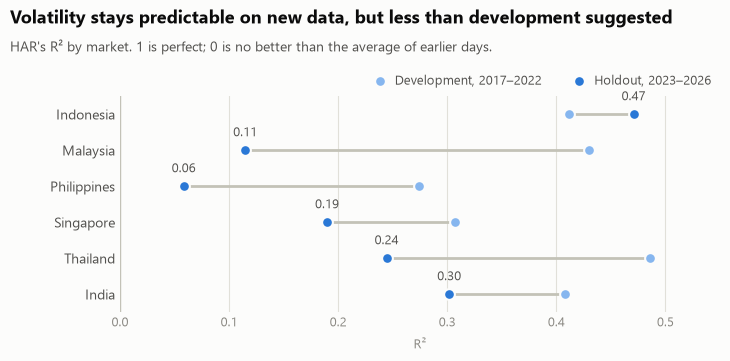

In [8]:
development = pd.Series({market: r2(pd.read_pickle(RESULTS / f"har_{market}.pkl")) for market in MARKETS})
holdout = volatility.loc["HAR R2", "value"]

fig, ax = new_chart("Volatility stays predictable on new data, but less than development suggested",
                    "HAR's R² by market. 1 is perfect; 0 is no better than the average of earlier days.",
                    MARKETS, "R²", left=1.3)
ax.hlines(range(len(MARKETS)), development, holdout, color=AXIS, linewidth=2)
dots(ax, development, color=LIGHT_BLUE, label="Development, 2017–2022")
dots(ax, holdout, label="Holdout, 2023–2026")
for row, value in enumerate(holdout):
    ax.text(value, row - 0.32, f"{value:.2f}", fontsize=9, color=INK_SOFT, ha="center", va="bottom")
ax.set_xlim(0, 0.55)
ax.axvline(0, color=AXIS, linewidth=1)
ax.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=2, frameon=False, fontsize=9, labelcolor=INK_SOFT,
          handletextpad=0.2, borderaxespad=0.3)
save(fig, "holdout_volatility.png")